In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os
import warnings

os.environ["TQDM_DISABLE"] = "1"
# plot_swanson_vector warns about regions with no value; the plot is correct
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

# From coordinates to a brain figure

You have some points in the brain, with a measurement at each one. Which brain region is each
point in, and what do the measurements look like across regions? This tutorial goes from a list
of coordinates to a figure of the brain coloured by region.

It uses stand-in data made in the notebook. If you have not installed `iblatlas` yet, see
[Install iblatlas](../how-to/install.qmd).

## 1. Load the atlas

The atlas holds the Allen mouse brain volumes and the brain region tree. Coordinates are in metres,
relative to bregma, in the order ML, AP, DV, with DV negative going down into the brain. See
[Coordinates and volumes](../explanation/coordinates-and-volumes.qmd). The first time you create it, the atlas
downloads about 40 MB; see [Data downloads and caching](../explanation/data-downloads-and-caching.qmd).

In [2]:
from iblatlas.atlas import AllenAtlas

ba = AllenAtlas()

## 2. Your data

Here the points are the 384 channels of one vertical probe, with a value at each channel. Track
positions from histology registration tools usually come in Allen CCF micrometres, so the probe is
defined in CCF µm and converted to atlas coordinates with `ccf2xyz`. See
[The Allen CCF frame and the IBL frame](../explanation/atlas-spaces.qmd#the-allen-ccf-frame-and-the-ibl-frame).

In [3]:
import numpy as np

# Stand-in for your own data: replace ccf_um with your points in CCF micrometres (ML, AP, DV)
# and values with your measurement at each point.
top_um = np.array([4539, 6900, 92])     # ML, AP, DV of the top channel, CCF µm
tip_um = np.array([4539, 6900, 3932])   # ML, AP, DV of the tip channel, CCF µm
ccf_um = np.linspace(top_um, tip_um, 384)

rng = np.random.default_rng(0)
# stand-in for a value per channel, such as a firing rate, rising with depth
values = rng.gamma(2, 2, 384) * np.linspace(1, 5, 384)

xyz = ba.ccf2xyz(ccf_um)  # metres relative to bregma, ML, AP, DV
xyz[[0, -1]]  # the top and the tip

array([[-0.0012 , -0.0015 ,  0.00024],
       [-0.0012 , -0.0015 , -0.0036 ]])

## 3. Which region is each point in?

`get_labels` returns the Allen id of the region at each point, and `id2acronym` turns the ids into
acronyms. See [The brain region hierarchy](../explanation/brain-region-hierarchy.qmd#three-identifiers-and-they-are-not-interchangeable)
for how ids and acronyms relate.

In [4]:
import pandas as pd

df = pd.DataFrame(xyz, columns=['ml', 'ap', 'dv'])
df['value'] = values
df['atlas_id'] = ba.get_labels(xyz)
df['acronym'] = ba.regions.id2acronym(df['atlas_id'])
df.head()

,ml,ap,dv,value,atlas_id,acronym
0,-0.0012,-0.0015,0.00024,3.668620,0,void
1,-0.0012,-0.0015,0.00023,5.330491,0,void
2,-0.0012,-0.0015,0.00022,2.177264,0,void
3,-0.0012,-0.0015,0.00021,8.210517,0,void
4,-0.0012,-0.0015,0.00020,1.902763,0,void


The top channels are labelled `void`: they are above the brain. Drop them before summarising.

In [5]:
print(f"{(df['acronym'] == 'void').sum()} channels are outside the brain")
df = df[df['acronym'] != 'void']

22 channels are outside the brain


## 4. Check by eye

Draw the coronal slice at the probe's AP position and put each channel on it, coloured by the
region it was assigned. Each dot sits in a region of the same colour. The slice is drawn in
micrometres, so the coordinates are multiplied by `1e6`; see
[Index versus coordinate](../explanation/coordinates-and-volumes.qmd#index-versus-coordinate).

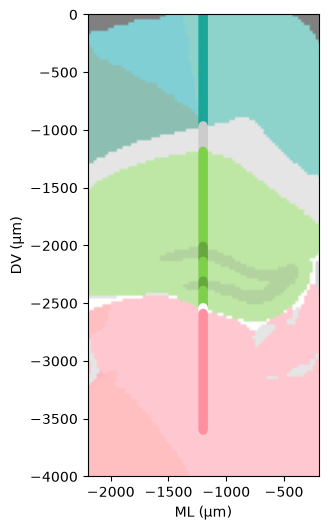

In [6]:
import matplotlib.pyplot as plt

ap = df['ap'].iloc[0]
fig, ax = plt.subplots(figsize=(8, 6))
ba.plot_cslice(ap, volume='annotation', ax=ax, alpha=0.5)
colours = ba.regions.get(df['atlas_id'])['rgb'] / 255
ax.scatter(df['ml'] * 1e6, df['dv'] * 1e6, c=colours, s=30)  # metres to micrometres
ax.set(xlim=(-2200, -200), ylim=(-4000, 0), xlabel='ML (µm)', ylabel='DV (µm)');

## 5. Group fine regions into coarser ones

The Allen regions are fine: cortex is split into layers, for example. The Beryl mapping groups them
into larger regions. Ask `get_labels` for Beryl ids and convert them to acronyms as before. See
[The four mappings](../explanation/brain-region-mappings.qmd#the-four-mappings) and
[Regions form a tree](../explanation/brain-region-hierarchy.qmd#regions-form-a-tree).

In [7]:
df['beryl'] = ba.regions.id2acronym(ba.get_labels(df[['ml', 'ap', 'dv']].to_numpy(), mapping='Beryl'))
df[['acronym', 'beryl']].drop_duplicates()

,acronym,beryl
22,RSPagl1,RSPagl
32,RSPagl2/3,RSPagl
57,RSPagl5,RSPagl
92,RSPagl6a,RSPagl
117,RSPagl6b,RSPagl
120,cing,root
130,ccb,root
137,alv,root
142,CA1,CA1
202,DG-mo,DG


`root` marks fibre tracts and ventricles, which Beryl does not name.

## 6. Summarise per region

Average the values in each Beryl region.

In [8]:
per_region = df[df['beryl'] != 'root'].groupby('beryl')['value'].mean()
per_region

beryl
CA1       11.842493
CA3       11.364180
DG        14.356074
Eth       16.960236
LD        14.456146
LP        16.659932
PO        18.022231
RSPagl     6.914807
Name: value, dtype: float64

## 7. Plot per region

Colour each region by its mean value. Two views show the same eight numbers.

**On a slice.** `plot_scalar_on_slice` draws the coronal slice at the probe's AP position and fills
each Beryl region you pass in with the colour for its value. It takes acronyms and values as two
matching arrays, and `mapping='Beryl'` tells it which mapping the acronyms come from. The probe is
in the left hemisphere, so `hemisphere='left'` fills only that side. `background='boundary'`
draws the outlines of all regions, and the regions with no value stay white. A slice only shows the
regions it cuts through, so a region the probe crossed at another AP position would not appear
here.

**On the Swanson flat map.** The Swanson map unfolds one hemisphere of the brain onto a single
flat drawing, so every region is visible at once whatever its position. Regions with no value are
drawn in `empty_color`, here silver. Not every region has a patch on the map; see
[The Swanson mapping](../explanation/brain-region-mappings.qmd#the-swanson-mapping) for which regions it
can show.

In both plots the colour bar gives the value for each colour.

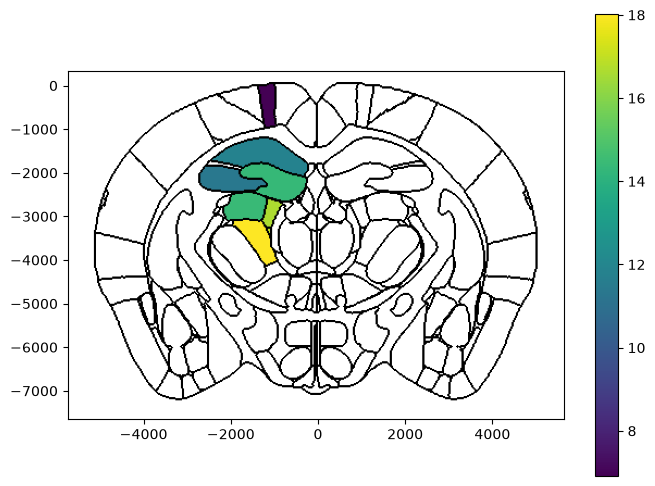

In [9]:
from iblatlas.plots import plot_scalar_on_slice, plot_swanson_vector

fig, ax = plt.subplots(figsize=(8, 6))
plot_scalar_on_slice(per_region.index.to_numpy(), per_region.to_numpy(), coord=ap * 1e6,
                     slice='coronal', mapping='Beryl', hemisphere='left', background='boundary',
                     cmap='viridis', show_cbar=True, brain_atlas=ba, ax=ax);

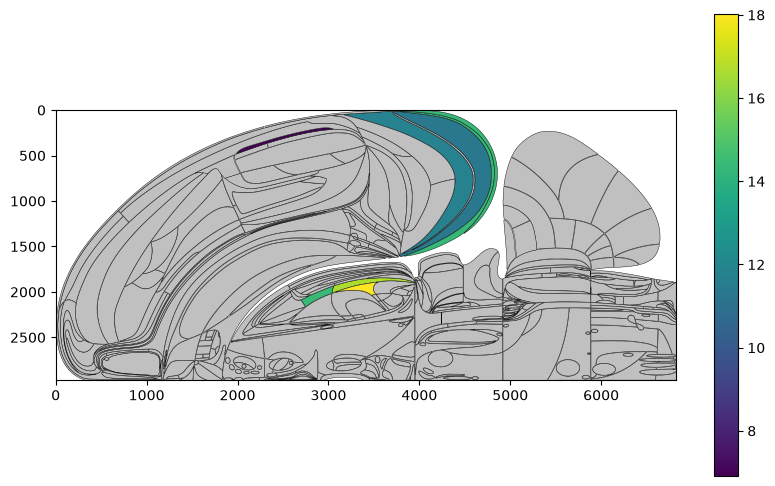

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_swanson_vector(per_region.index.to_numpy(), per_region.to_numpy(), br=ba.regions, cmap='viridis',
                    empty_color='silver', show_cbar=True, ax=ax);

## 8. Where next

- Bring your own points: [Convert coordinates from the Allen CCF or a registration tool](../how-to/bring-your-own-coordinates.ipynb)
- Work with region names: [Convert region ids between mappings](../how-to/remap-region-ids.ipynb) and
  [Navigate the brain region hierarchy](../how-to/navigate-the-region-hierarchy.ipynb)
- Other ways to show results: [Show one value per region on slices](../how-to/plot-values-on-slices.ipynb)
  and [Show values per point or cell on slices](../how-to/plot-points-on-slices.ipynb)
- Probes: [From a target to a probe track](from-a-target-to-a-probe-track.ipynb) and
  [Describe a probe insertion and list the regions it crosses](../how-to/work-with-probe-insertions.qmd)
- Compare with gene expression, cell types, lipids and connectivity:
  [From your results to what's known](from-your-results-to-whats-known.ipynb) and
  [External data in the common space](../explanation/external-data-in-the-common-space.qmd)